# Statistical Time Series Forecasting — Delhi AQI

This notebook focuses on building and evaluating statistical time-series forecasting models for daily Air Quality Index (AQI) in Delhi. We will first understand the temporal structure of the AQI series through trend, seasonality, rolling statistics, decomposition, stationarity testing, and ACF/PACF analysis. We will then establish Naive and Seasonal Naive forecasting baselines before developing ARIMA, SARIMA, and Fourier-based forecasting models. Models will be evaluated using a chronological train-validation-test framework with MAE, RMSE, and MAPE, and the final statistical model will be selected based on out-of-sample forecasting performance.

## 1. Objectives

The main objectives of this notebook are:

- Prepare the Delhi AQI series for time-series forecasting.
- Understand trend, seasonality, autocorrelation, and volatility.
- Test whether the AQI series is stationary.
- Analyze ACF and PACF to identify temporal dependencies.
- Establish Naive and Seasonal Naive benchmark models.
- Build and compare ARIMA and SARIMA models.
- Model annual seasonality using Fourier terms.
- Use a validation set for model selection and keep the final test set untouched.
- Evaluate the final forecasting model using MAE, RMSE, and MAPE.
- Establish a strong statistical forecasting benchmark for comparison with future Machine Learning and Deep Learning models.

## 2. Import Libraries

We begin by importing the Python libraries required for time-series analysis, statistical modeling, visualization, and model evaluation.

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

## 3. Load the Preprocessed Delhi AQI Data

The previous notebook completed the required data cleaning and preprocessing. In this notebook, we work with the prepared Delhi AQI time series and focus specifically on forecasting.

In [58]:
df = pd.read_csv(
    "../data/processed/delhi_aqi_timeseries.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date")

df.head()

,Date,AQI
0,2015-01-01,472.0
1,2015-01-02,454.0
2,2015-01-03,143.0
3,2015-01-04,319.0
4,2015-01-05,325.0


In [59]:
print("Shape:", df.shape)
print("Start:", df["Date"].min())
print("End:", df["Date"].max())
print("Missing AQI:", df["AQI"].isna().sum())

Shape: (2009, 2)
Start: 2015-01-01 00:00:00
End: 2020-07-01 00:00:00
Missing AQI: 0


In [60]:
df = df.set_index("Date")

df = df.sort_index()

df.head()

,AQI
Date,
2015-01-01,472.0
2015-01-02,454.0
2015-01-03,143.0
2015-01-04,319.0
2015-01-05,325.0


In [61]:
print(df.index)
print(df.shape)

DatetimeIndex(['2015-01-01', '2015-01-02', '2015-01-03', '2015-01-04',
               '2015-01-05', '2015-01-06', '2015-01-07', '2015-01-08',
               '2015-01-09', '2015-01-10',
               ...
               '2020-06-22', '2020-06-23', '2020-06-24', '2020-06-25',
               '2020-06-26', '2020-06-27', '2020-06-28', '2020-06-29',
               '2020-06-30', '2020-07-01'],
              dtype='datetime64[us]', name='Date', length=2009, freq=None)
(2009, 1)


## 4. Define the Target Time Series

For this notebook, the forecasting target is the daily AQI of Delhi. Since the data has already been cleaned and missing AQI observations have been handled in the preprocessing stage, we can directly use the AQI column as our univariate time series.

The Date column is converted into the time-series index so that the observations are ordered chronologically and can be used correctly by statistical forecasting models.

In [62]:
aqi = df["AQI"].copy()

print("Number of observations:", len(aqi))
print("Start date:", aqi.index.min())
print("End date:", aqi.index.max())
print("Missing values:", aqi.isna().sum())

Number of observations: 2009
Start date: 2015-01-01 00:00:00
End date: 2020-07-01 00:00:00
Missing values: 0


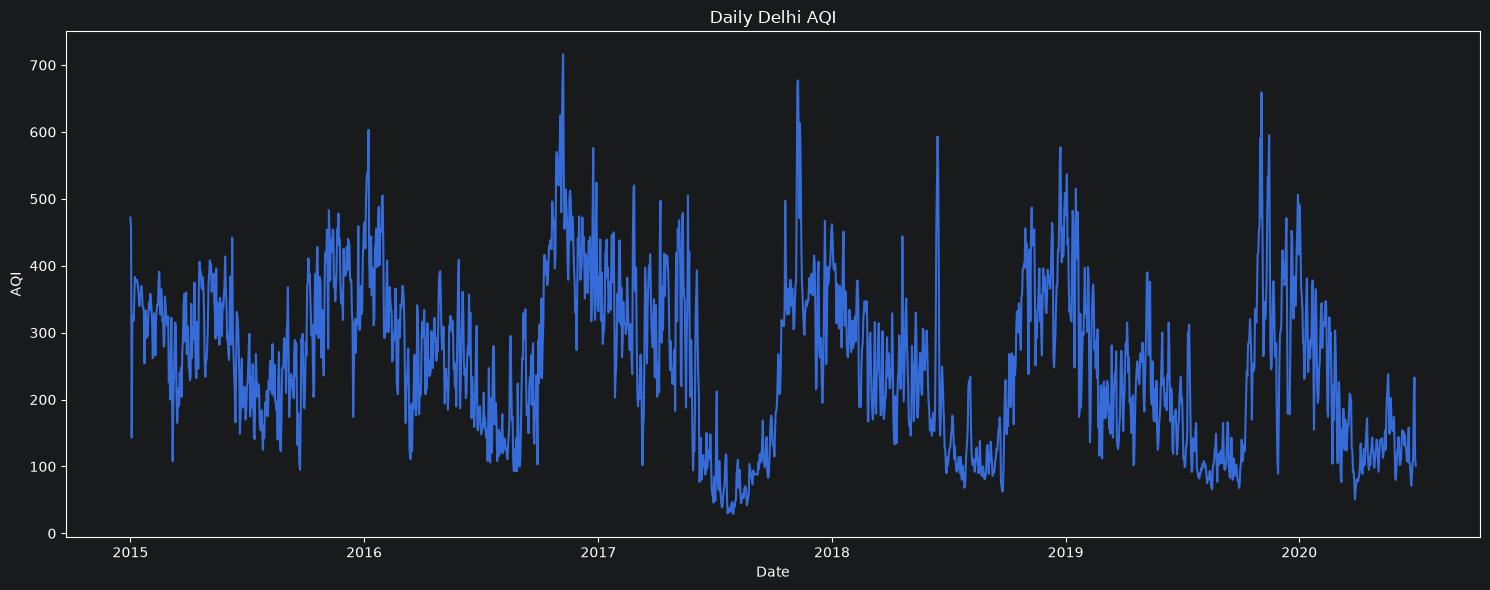

In [63]:
plt.figure(figsize=(15, 6))

plt.plot(aqi)

plt.title("Daily Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")

plt.tight_layout()
plt.show()

## 5. Trend and Seasonality Analysis

Before selecting a forecasting model, we need to understand the major temporal patterns in Delhi AQI. We will examine the series at different time scales to identify long-term trends and recurring seasonal behavior.

We will analyze:

- Monthly average AQI to understand within-year seasonal patterns.
- Yearly average AQI to examine long-term changes.
- Rolling statistics to understand local trends and volatility.
- Time-series decomposition to separate trend, seasonal, and residual components.

In [64]:
monthly_aqi = aqi.groupby(aqi.index.month).mean()

monthly_aqi

Date
1     360.387097
2     298.829412
3     222.623656
4     248.444444
5     258.693548
6     198.963889
7     137.839744
8     131.103226
9     157.426667
10    312.329032
11    401.953333
12    371.206452
Name: AQI, dtype: float64

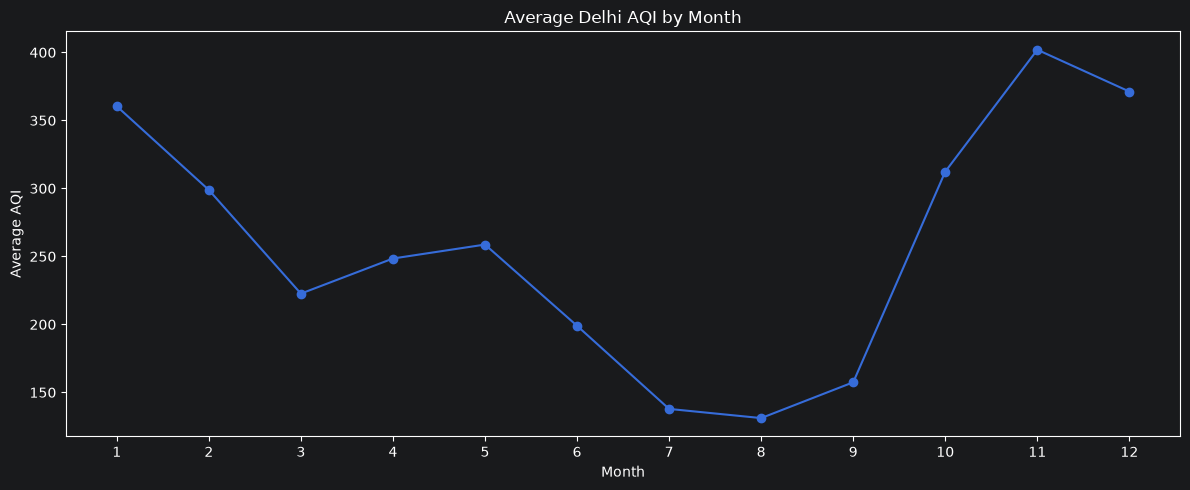

In [65]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_aqi.index,
    monthly_aqi.values,
    marker="o"
)

plt.title("Average Delhi AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [66]:
yearly_aqi = aqi.groupby(aqi.index.year).mean()

yearly_aqi

Date
2015    297.024658
2016    301.035519
2017    252.247945
2018    249.158904
2019    232.104110
2020    181.672131
Name: AQI, dtype: float64

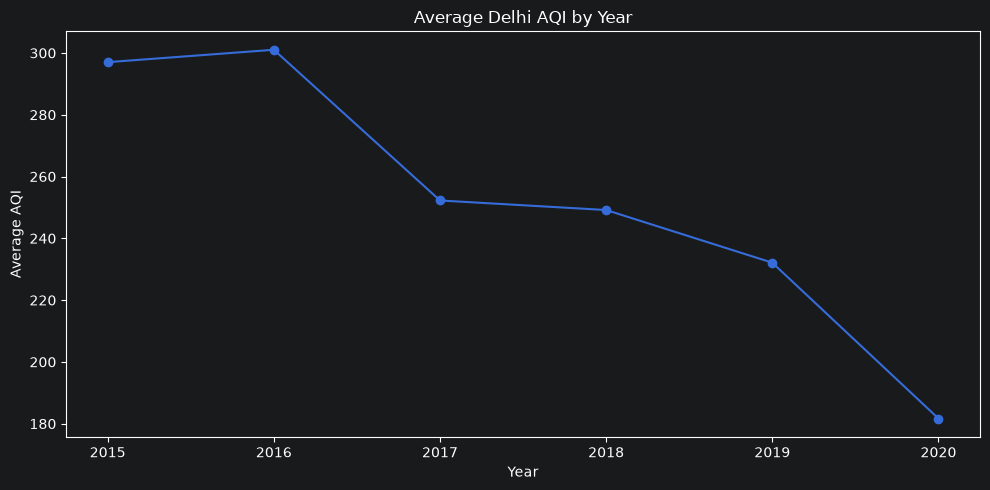

In [67]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_aqi.index,
    yearly_aqi.values,
    marker="o"
)

plt.title("Average Delhi AQI by Year")
plt.xlabel("Year")
plt.ylabel("Average AQI")

plt.tight_layout()
plt.show()

### Observations

The monthly analysis reveals a strong annual seasonal pattern in Delhi AQI. AQI is substantially higher during October to January, with November showing the highest average AQI of approximately 401.95, while July and August show the lowest average levels.

The yearly averages show that Delhi's average AQI was relatively high during 2015–2016 and then declined from 2017 onward. The 2020 value should be interpreted cautiously because the dataset ends on July 1, 2020 and therefore does not represent a complete calendar year.

These observations indicate that both seasonality and longer-term changes in the series need to be considered during the forecasting stage.

## 6. Rolling Statistics

Rolling statistics help us examine how the local behavior of the time series changes over time. We will calculate a 30-day rolling mean and standard deviation.

The rolling mean helps identify short-term changes in the local level of AQI, while the rolling standard deviation helps us understand changes in volatility.

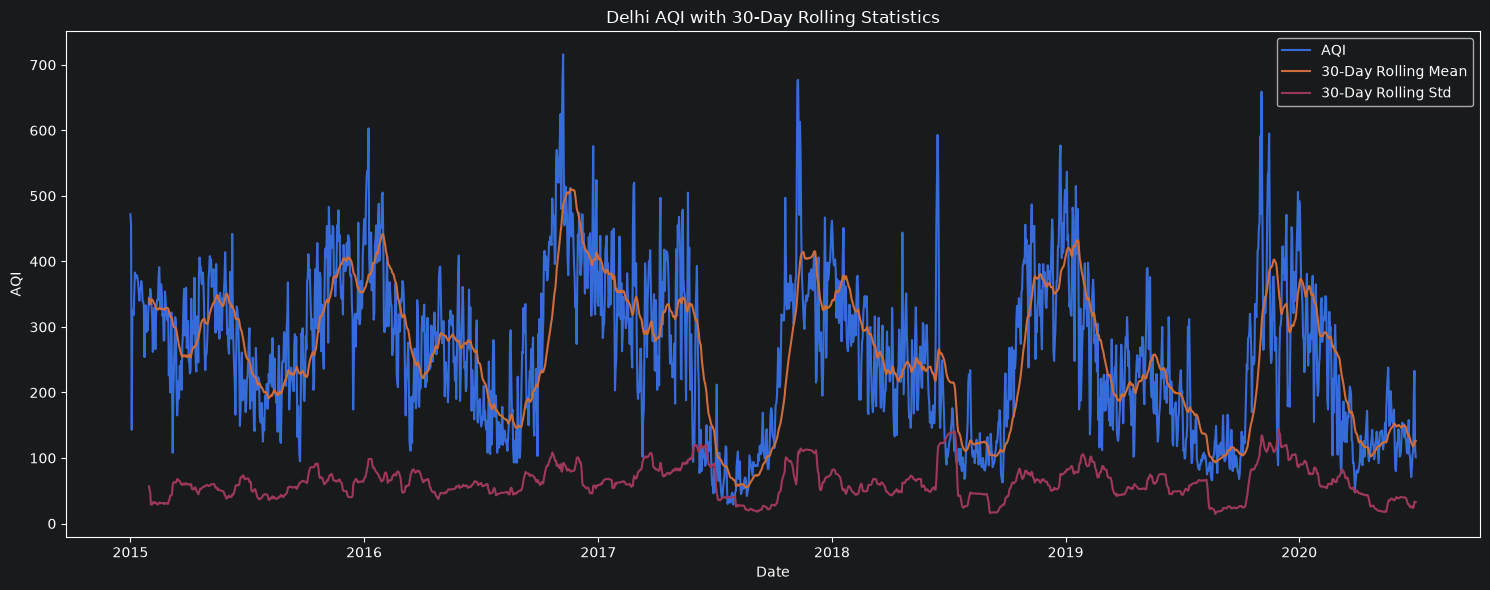

In [68]:
rolling_mean = aqi.rolling(window=30).mean()
rolling_std = aqi.rolling(window=30).std()

plt.figure(figsize=(15, 6))

plt.plot(aqi, label="AQI")
plt.plot(rolling_mean, label="30-Day Rolling Mean")
plt.plot(rolling_std, label="30-Day Rolling Std")

plt.title("Delhi AQI with 30-Day Rolling Statistics")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

### Observations

The 30-day rolling mean reveals repeated rises and falls in Delhi AQI, supporting the presence of a strong recurring seasonal pattern. The rolling standard deviation also changes substantially over time, indicating that the variability of AQI is not constant.

The combination of changing local levels and changing volatility suggests that the series has complex temporal behavior. These observations motivate further analysis using time-series decomposition and stationarity testing before selecting forecasting models.

## 7. Time-Series Decomposition

Time-series decomposition separates the observed AQI series into three components:

- **Trend:** the underlying long-term movement in AQI.
- **Seasonal:** the recurring pattern within a year.
- **Residual:** the remaining variation that is not explained by the trend and seasonal components.

Since the exploratory analysis indicated strong yearly seasonality, a seasonal period of 365 days is used for the decomposition.

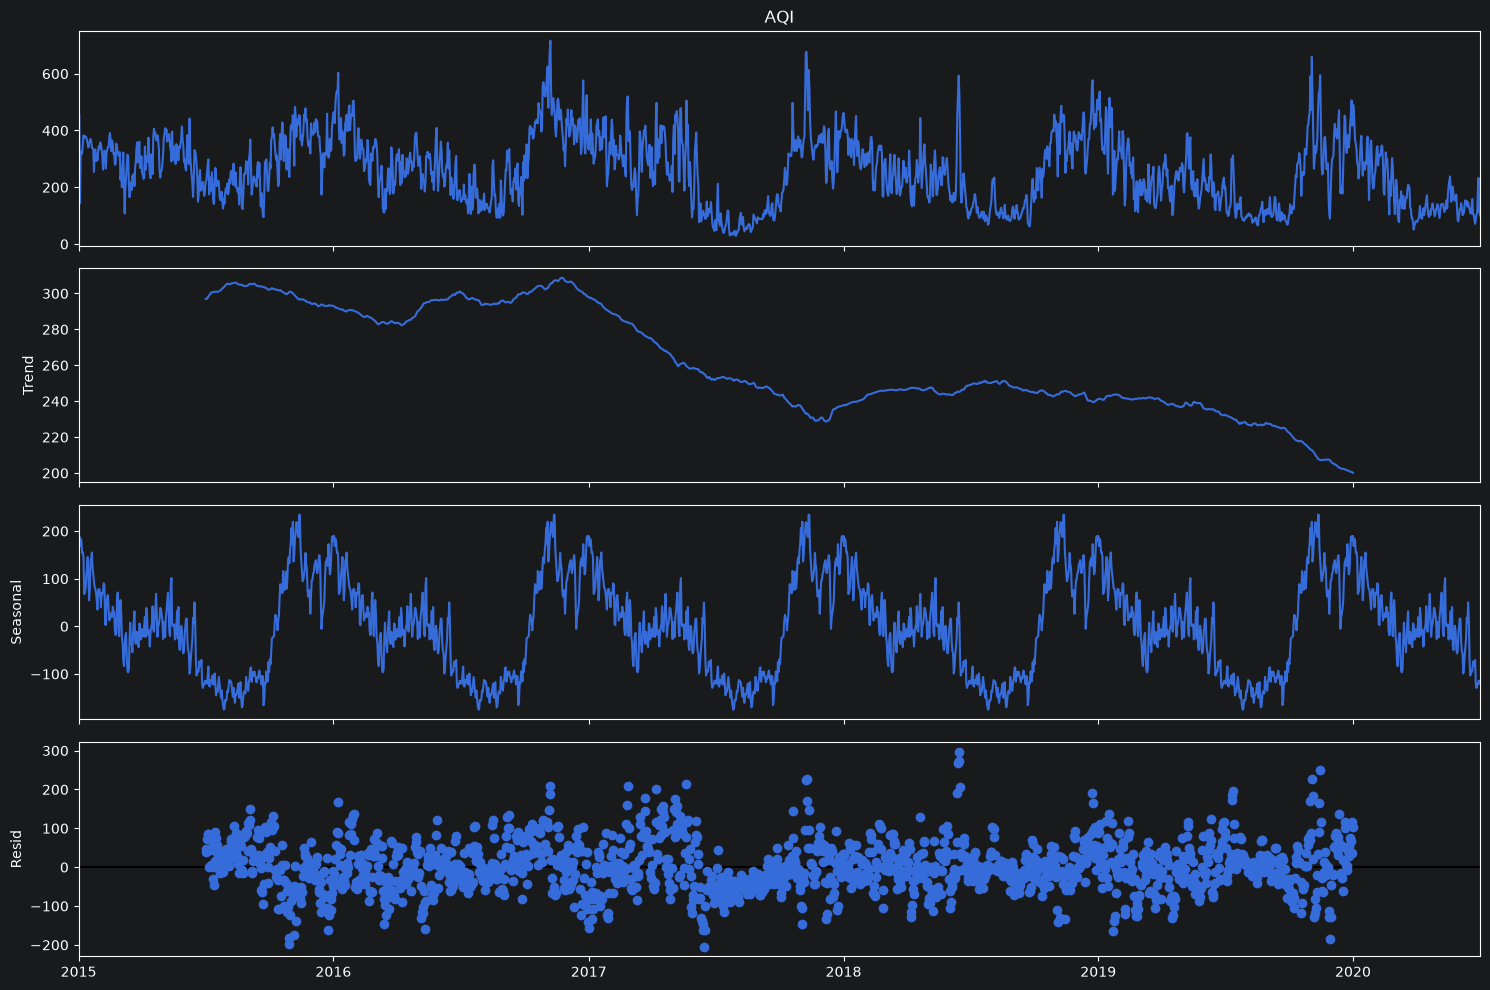

In [69]:
decomposition = seasonal_decompose(
    aqi,
    model="additive",
    period=365
)

fig = decomposition.plot()

fig.set_size_inches(15, 10)

plt.tight_layout()
plt.show()

### Decomposition Observations

The decomposition confirms the presence of three important components in Delhi AQI. The trend component indicates a gradual decline in the underlying AQI level over the later part of the dataset. The seasonal component shows a strong and repeating annual pattern, supporting the use of a 365-day seasonal period. The residual component remains centered approximately around zero but contains substantial variation and several extreme observations, indicating that short-term fluctuations are not completely explained by the trend and seasonal components.

Overall, the decomposition provides strong evidence that annual seasonality is an important component of Delhi AQI and should be explicitly considered in the forecasting models.

## 8. Stationarity Analysis

Many classical time-series models, particularly ARIMA-type models, rely on the concept of stationarity. A stationary series has statistical properties such as its mean and variance that remain reasonably stable over time.

We will use the Augmented Dickey-Fuller (ADF) test to determine whether the AQI series contains a unit root.

### Hypotheses

- **H₀:** The time series has a unit root and is non-stationary.
- **H₁:** The time series is stationary.

A small p-value provides evidence against H₀ and supports stationarity.

In [70]:
adf_result = adfuller(aqi.dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Number of Lags Used:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("\nCritical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -3.431934347253973
p-value: 0.009917226121156647
Number of Lags Used: 17
Number of Observations: 1991

Critical Values:
1%: -3.4336386745240652
5%: -2.8629927557359443
10%: -2.5675433856598793


### ADF Test Result

The ADF statistic is approximately -3.43 with a p-value of approximately 0.0099. Since the p-value is below the 0.05 significance level, we reject the null hypothesis of a unit root.

Therefore, the AQI series can be considered stationary according to the ADF test at the 5% significance level. Consequently, we begin the ARIMA modeling process with no non-seasonal differencing, corresponding to d = 0.

However, stationarity according to the ADF test does not eliminate the strong annual seasonal pattern identified earlier. Seasonal dependence will therefore be investigated separately using autocorrelation analysis.

### ADF Test Interpretation

The Augmented Dickey-Fuller test produced an ADF statistic of -3.4319 and a p-value of 0.0099.

At the 5% significance level, the p-value is below 0.05, so we reject the null hypothesis of a unit root and conclude that the AQI series is stationary according to the ADF test.

The ADF statistic is very close to the 1% critical value (-3.4336), but it is slightly greater than it. Therefore, the null hypothesis cannot be rejected at the 1% significance level.

Overall, the series provides sufficient evidence of stationarity at the 5% significance level. Based on this result, we initially use d = 0 when evaluating ARIMA models rather than automatically applying non-seasonal differencing.

## 9. Autocorrelation Analysis

Autocorrelation measures how strongly the current AQI is related to its previous values at different time lags.

We will use:

- **ACF (Autocorrelation Function):** measures the correlation between the series and its lagged values.
- **PACF (Partial Autocorrelation Function):** measures the direct relationship between the series and a particular lag after removing the effects of intermediate lags.

These plots help identify potential autoregressive (AR) and moving-average (MA) structures for ARIMA modeling.

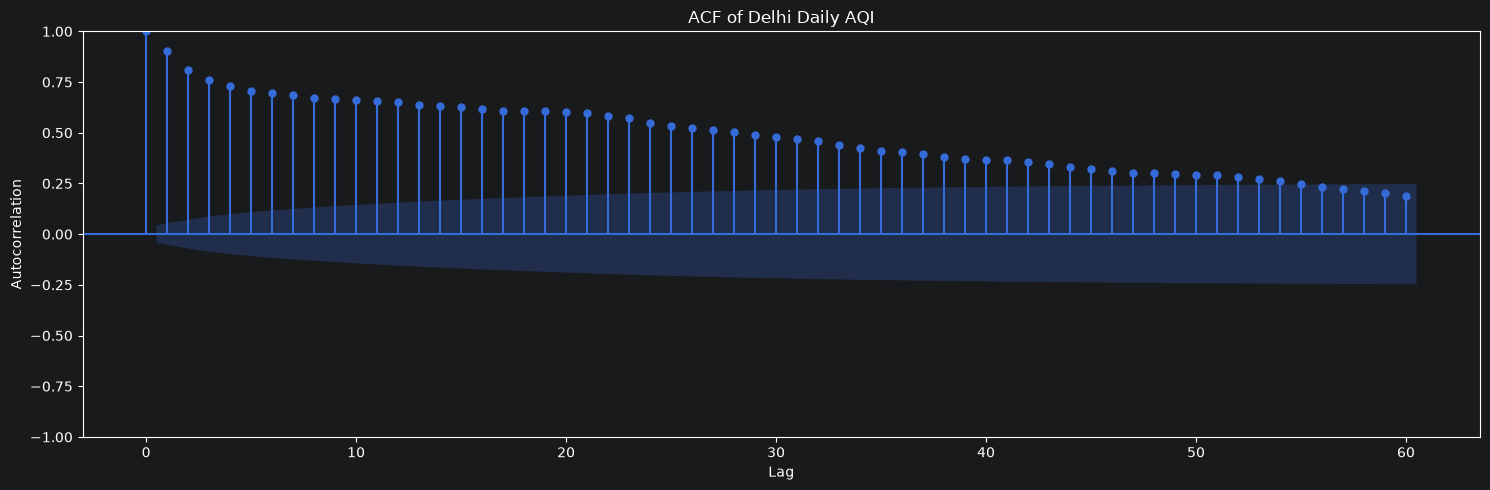

In [71]:
fig, ax = plt.subplots(figsize=(15, 5))

plot_acf(
    aqi,
    lags=60,
    ax=ax
)

ax.set_title("ACF of Delhi Daily AQI")
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

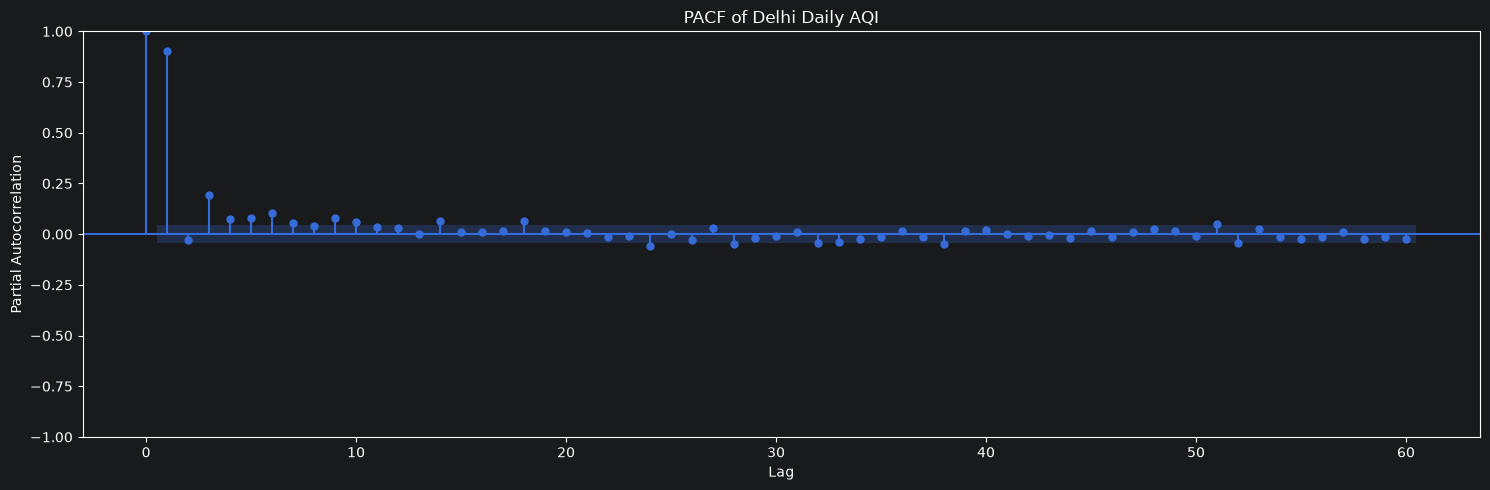

In [72]:
fig, ax = plt.subplots(figsize=(15, 5))

plot_pacf(
    aqi,
    lags=60,
    ax=ax,
    method="ywm"
)

ax.set_title("PACF of Delhi Daily AQI")
ax.set_xlabel("Lag")
ax.set_ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()

## 10. Seasonal Autocorrelation Analysis

The exploratory analysis identified a strong annual seasonal pattern. We therefore examine autocorrelation at longer and meaningful seasonal lags.

For daily AQI, important lags include:

- **7 days:** weekly behavior
- **14 days:** two-week relationship
- **30 days:** approximately monthly behavior
- **365 days:** annual seasonality

These correlations help determine whether seasonal components should be explicitly incorporated into the forecasting model.

In [73]:
seasonal_lags = [7, 14, 30, 90, 180, 365]

for lag in seasonal_lags:
    correlation = aqi.autocorr(lag=lag)
    print(f"Lag {lag}: {correlation:.4f}")

Lag 7: 0.6867
Lag 14: 0.6367
Lag 30: 0.4847
Lag 90: -0.1098
Lag 180: -0.1843
Lag 365: 0.6236


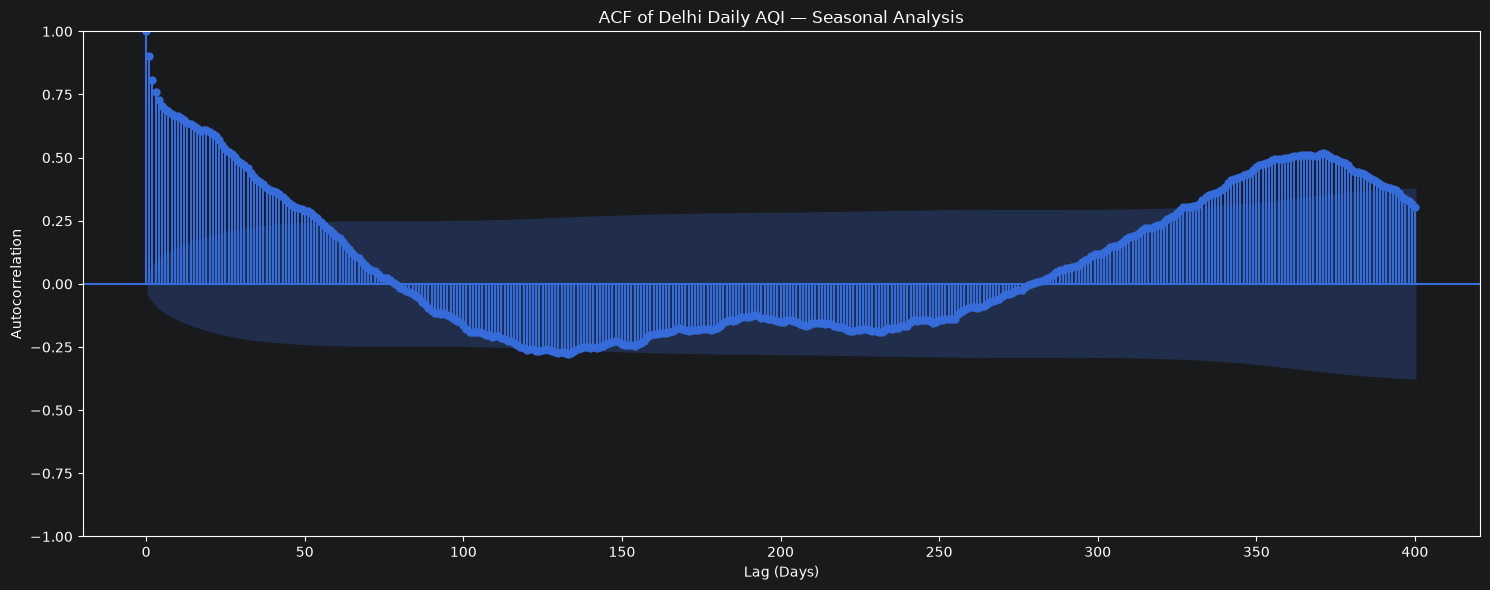

In [74]:
fig, ax = plt.subplots(figsize=(15, 6))

plot_acf(
    aqi,
    lags=400,
    ax=ax
)

ax.set_title("ACF of Delhi Daily AQI — Seasonal Analysis")
ax.set_xlabel("Lag (Days)")
ax.set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

### ACF and Seasonal Analysis — Observations

The ACF shows strong positive autocorrelation at short lags, indicating that recent AQI observations contain substantial information about future AQI.

The seasonal lag analysis reveals strong dependence at both weekly and annual frequencies. The correlation at lag 7 is approximately 0.687, while the correlation at lag 365 is approximately 0.624. The strong correlation at lag 365 provides clear evidence of recurring annual behavior.

Therefore, Delhi AQI contains multiple temporal structures: short-term dependence, weekly dependence, and strong annual seasonality. This motivates evaluating both autoregressive models and models capable of explicitly representing seasonal behavior.

## 11. Chronological Train–Validation–Test Split

Time-series forecasting requires a chronological split because future observations must never be used to train a model that is intended to predict the past.

The data is divided into three sequential periods:

- **Training set:** 2015-01-01 to 2018-07-02
- **Validation set:** 2018-07-03 to 2019-07-02
- **Test set:** 2019-07-03 to 2020-07-01

The validation set is used for model and hyperparameter selection, while the final test set remains untouched until the final evaluation.

In [75]:
train_size = 1279
validation_size = 365

train = aqi.iloc[:train_size].copy()
validation = aqi.iloc[train_size:train_size + validation_size].copy()
test = aqi.iloc[train_size + validation_size:].copy()

print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nValidation period:")
print(validation.index.min(), "to", validation.index.max())

print("\nTest period:")
print(test.index.min(), "to", test.index.max())

Training: 1279
Validation: 365
Test: 365

Training period:
2015-01-01 00:00:00 to 2018-07-02 00:00:00

Validation period:
2018-07-03 00:00:00 to 2019-07-02 00:00:00

Test period:
2019-07-03 00:00:00 to 2020-07-01 00:00:00


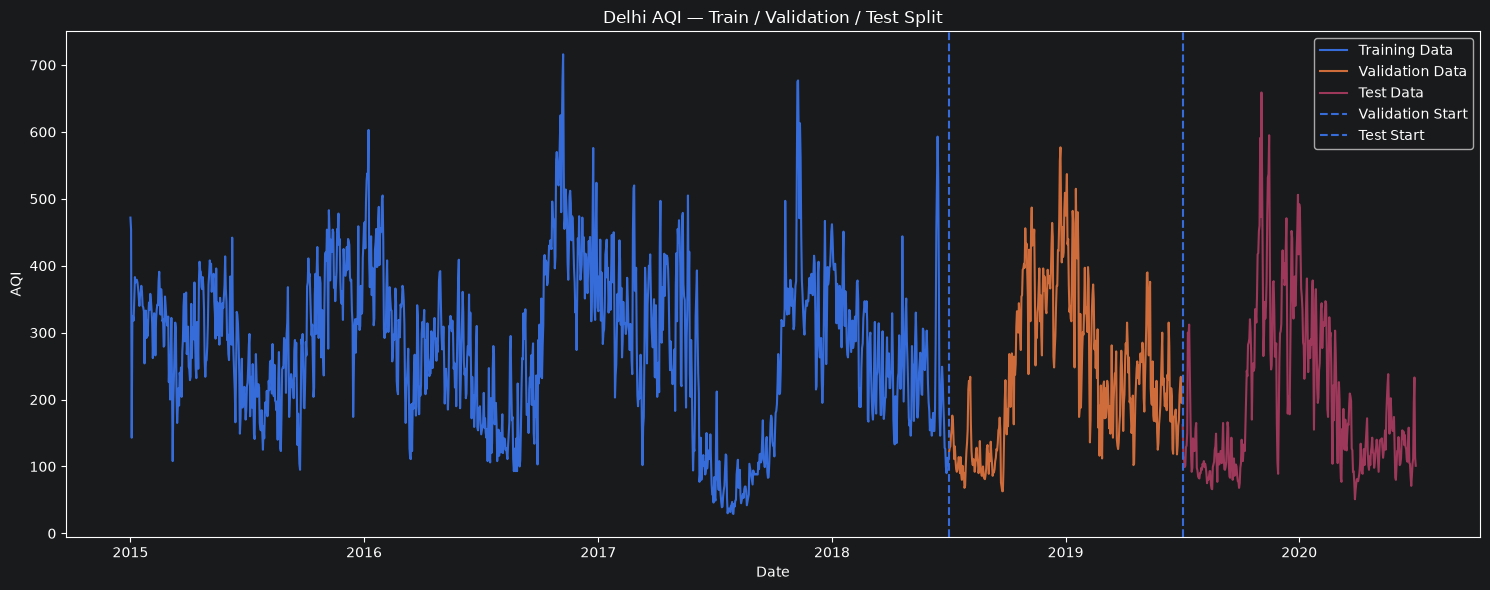

In [76]:
plt.figure(figsize=(15, 6))

plt.plot(train.index, train, label="Training Data")
plt.plot(validation.index, validation, label="Validation Data")
plt.plot(test.index, test, label="Test Data")

plt.axvline(
    validation.index[0],
    linestyle="--",
    label="Validation Start"
)

plt.axvline(
    test.index[0],
    linestyle="--",
    label="Test Start"
)

plt.title("Delhi AQI — Train / Validation / Test Split")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

### Train–Validation–Test Split — Observation

The chronological split preserves the temporal ordering of the AQI observations. The training period contains the earliest observations, followed by a one-year validation period and a final one-year test period.

The validation period will be used for comparing model configurations and selecting hyperparameters. The final test period will remain untouched until the final evaluation, providing an unbiased estimate of how the selected forecasting model performs on unseen future observations.

## 12. Baseline Forecasting

Baseline models provide simple reference points against which more sophisticated forecasting models can be evaluated.

We use two benchmarks:

1. **Naive Forecast:** predicts the next value using the most recently observed AQI.
2. **Seasonal Naive Forecast:** predicts the AQI using the value observed at the same position one year earlier.

Because the data exhibits strong annual seasonality, the seasonal-naive model provides a particularly meaningful benchmark.

In [77]:
naive_validation_forecast = pd.Series(
    train.iloc[-1],
    index=validation.index
)

naive_validation_forecast.head()

Date
2018-07-03    111.0
2018-07-04    111.0
2018-07-05    111.0
2018-07-06    111.0
2018-07-07    111.0
dtype: float64

In [78]:
print("Last training AQI:", train.iloc[-1])
print("\nFirst 5 naive validation predictions:")
print(naive_validation_forecast.head())

Last training AQI: 111.0

First 5 naive validation predictions:
Date
2018-07-03    111.0
2018-07-04    111.0
2018-07-05    111.0
2018-07-06    111.0
2018-07-07    111.0
dtype: float64


In [79]:
seasonal_naive_validation_forecast = train.iloc[-365:].copy()

seasonal_naive_validation_forecast.index = validation.index
seasonal_naive_validation_forecast.head()

Date
2018-07-03     49.0
2018-07-04    149.0
2018-07-05    212.0
2018-07-06     85.0
2018-07-07     77.0
Name: AQI, dtype: float64

In [80]:
print("First 5 seasonal naive predictions:")
print(seasonal_naive_validation_forecast.head())

First 5 seasonal naive predictions:
Date
2018-07-03     49.0
2018-07-04    149.0
2018-07-05    212.0
2018-07-06     85.0
2018-07-07     77.0
Name: AQI, dtype: float64


In [81]:
def evaluate_forecast(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    # Ignore observations where actual value is zero
    mask = actual != 0

    mape = np.mean(
        np.abs(
            (actual[mask] - predicted[mask]) / actual[mask]
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

In [82]:
naive_validation_metrics = evaluate_forecast(
    validation,
    naive_validation_forecast
)
naive_validation_metrics

{'MAE': 135.0849315068493,
 'RMSE': np.float64(173.62436228272284),
 'MAPE': np.float64(46.63206631744504)}

In [83]:
seasonal_naive_validation_metrics = evaluate_forecast(
    validation,
    seasonal_naive_validation_forecast
)
seasonal_naive_validation_metrics

{'MAE': 66.38794520547945,
 'RMSE': np.float64(88.68944191992061),
 'MAPE': np.float64(32.316793679719325)}

In [84]:
print(aqi.loc["2019-07-03":"2019-07-07"])

Date
2019-07-03    162.0
2019-07-04    111.0
2019-07-05    113.0
2019-07-06     99.0
2019-07-07    101.0
Name: AQI, dtype: float64


In [85]:
print(aqi.loc["2018-07-03":"2018-07-07"])

Date
2018-07-03    122.0
2018-07-04    128.0
2018-07-05    130.0
2018-07-06    147.0
2018-07-07    155.0
Name: AQI, dtype: float64


In [86]:
from statsmodels.tsa.arima.model import ARIMA

arima_orders = [
    (1, 0, 0),
    (2, 0, 0),
    (3, 0, 0),
    (1, 0, 1),
    (2, 0, 1),
    (1, 0, 2),
    (2, 0, 2)
]

arima_results = []

for order in arima_orders:

    print(f"Fitting ARIMA{order}...")

    model = ARIMA(
        train,
        order=order
    )

    fitted_model = model.fit()

    forecast = fitted_model.forecast(
        steps=len(validation)
    )

    forecast.index = validation.index

    metrics = evaluate_forecast(
        validation,
        forecast
    )

    arima_results.append({
        "Model": f"ARIMA{order}",
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MAPE": metrics["MAPE"]
    })

Fitting ARIMA(1, 0, 0)...
Fitting ARIMA(2, 0, 0)...
Fitting ARIMA(3, 0, 0)...
Fitting ARIMA(1, 0, 1)...
Fitting ARIMA(2, 0, 1)...
Fitting ARIMA(1, 0, 2)...
Fitting ARIMA(2, 0, 2)...


In [87]:
model_arima_100 = ARIMA(
    train,
    order=(1, 0, 0)
)

arima_100 = model_arima_100.fit()

print(arima_100.summary())

                               SARIMAX Results                                
Dep. Variable:                    AQI   No. Observations:                 1279
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -6912.960
Date:                Mon, 17 Aug 2026   AIC                          13831.920
Time:                        15:27:28   BIC                          13847.382
Sample:                    01-01-2015   HQIC                         13837.726
                         - 07-02-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        280.2713     13.639     20.549      0.000     253.539     307.004
ar.L1          0.8854      0.013     66.041      0.000       0.859       0.912
sigma2      2895.4524     86.074     33.639      0.0

In [88]:
forecast_arima_100 = arima_100.forecast(
    steps=len(validation)
)

forecast_arima_100.index = validation.index

forecast_arima_100.head()

Date
2018-07-03    130.401296
2018-07-04    147.578882
2018-07-05    162.787632
2018-07-06    176.253207
2018-07-07    188.175404
Name: predicted_mean, dtype: float64

In [89]:
arima_100_metrics = evaluate_forecast(
    validation,
    forecast_arima_100
)

arima_100_metrics

{'MAE': 101.14340406261765,
 'RMSE': np.float64(117.94720069610446),
 'MAPE': np.float64(62.6238846972592)}

In [90]:
arima_results = []

for order in arima_orders:

    print(f"Fitting ARIMA{order}...")

    model = ARIMA(
        train,
        order=order
    )

    fitted_model = model.fit()

    forecast = fitted_model.forecast(
        steps=len(validation)
    )

    forecast.index = validation.index

    metrics = evaluate_forecast(
        validation,
        forecast
    )

    arima_results.append({
        "Model": f"ARIMA{order}",
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MAPE": metrics["MAPE"]
    })

Fitting ARIMA(1, 0, 0)...
Fitting ARIMA(2, 0, 0)...
Fitting ARIMA(3, 0, 0)...
Fitting ARIMA(1, 0, 1)...
Fitting ARIMA(2, 0, 1)...
Fitting ARIMA(1, 0, 2)...
Fitting ARIMA(2, 0, 2)...


In [91]:
arima_results_df = pd.DataFrame(arima_results)

arima_results_df = arima_results_df.sort_values(
    "RMSE"
).reset_index(drop=True)

arima_results_df

,Model,AIC,BIC,MAE,RMSE,MAPE
0,"ARIMA(2, 0, 2)",13743.302269,13774.225272,90.394255,105.990094,50.647020
1,"ARIMA(1, 0, 2)",13773.710251,13799.479420,94.574313,110.786569,56.518949
2,"ARIMA(3, 0, 0)",13792.108886,13817.878055,99.342875,116.064017,60.997172
3,"ARIMA(1, 0, 0)",13831.920258,13847.381760,101.143404,117.947201,62.623885
4,"ARIMA(2, 0, 0)",13833.762446,13854.377782,101.234643,118.039058,62.704619
5,"ARIMA(1, 0, 1)",13833.654613,13854.269948,101.293421,118.097977,62.756605
6,"ARIMA(2, 0, 1)",13827.464698,13853.233867,101.443209,118.240962,62.887251


In [92]:
baseline_results = pd.DataFrame({
    "Naive": naive_validation_metrics,
    "Seasonal Naive": seasonal_naive_validation_metrics
}).T

baseline_results

,MAE,RMSE,MAPE
Naive,135.084932,173.624362,46.632066
Seasonal Naive,66.387945,88.689442,32.316794


In [93]:
comparison = pd.concat([
    baseline_results,
    arima_results_df.set_index("Model")[[
        "MAE",
        "RMSE",
        "MAPE"
    ]]
])

comparison = comparison.sort_values("RMSE")

comparison

,MAE,RMSE,MAPE
Seasonal Naive,66.387945,88.689442,32.316794
"ARIMA(2, 0, 2)",90.394255,105.990094,50.647020
"ARIMA(1, 0, 2)",94.574313,110.786569,56.518949
"ARIMA(3, 0, 0)",99.342875,116.064017,60.997172
"ARIMA(1, 0, 0)",101.143404,117.947201,62.623885
"ARIMA(2, 0, 0)",101.234643,118.039058,62.704619
"ARIMA(1, 0, 1)",101.293421,118.097977,62.756605
"ARIMA(2, 0, 1)",101.443209,118.240962,62.887251
Naive,135.084932,173.624362,46.632066


In [94]:
sarima_orders = [
    ((1, 0, 1), (1, 0, 1, 7)),
    ((2, 0, 2), (1, 0, 1, 7)),
    ((1, 0, 1), (1, 0, 0, 7)),
    ((1, 0, 1), (0, 0, 1, 7)),
    ((2, 0, 2), (1, 0, 0, 7))
]

sarima_results = []

In [95]:
for order, seasonal_order in sarima_orders:

    print(
        f"Fitting SARIMA{order}"
        f"x{seasonal_order}..."
    )

    model = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False)

    forecast = fitted_model.forecast(
        steps=len(validation)
    )

    forecast.index = validation.index

    metrics = evaluate_forecast(
        validation,
        forecast
    )

    sarima_results.append({
        "Model": f"SARIMA{order}x{seasonal_order}",
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MAPE": metrics["MAPE"]
    })

Fitting SARIMA(1, 0, 1)x(1, 0, 1, 7)...
Fitting SARIMA(2, 0, 2)x(1, 0, 1, 7)...
Fitting SARIMA(1, 0, 1)x(1, 0, 0, 7)...
Fitting SARIMA(1, 0, 1)x(0, 0, 1, 7)...
Fitting SARIMA(2, 0, 2)x(1, 0, 0, 7)...


In [96]:
sarima_results_df = pd.DataFrame(
    sarima_results
)

sarima_results_df = sarima_results_df.sort_values(
    "RMSE"
).reset_index(drop=True)

sarima_results_df

,Model,AIC,BIC,MAE,RMSE,MAPE
0,"SARIMA(2, 0, 2)x(1, 0, 1, 7)",13610.694432,13646.716323,141.782423,174.714829,53.102316
1,"SARIMA(2, 0, 2)x(1, 0, 0, 7)",13618.860246,13649.740879,143.214359,176.276439,53.550023
2,"SARIMA(1, 0, 1)x(1, 0, 0, 7)",13771.033204,13791.623441,222.086844,256.803936,85.354189
3,"SARIMA(1, 0, 1)x(1, 0, 1, 7)",13763.195905,13788.929766,222.088949,256.805190,85.355579
4,"SARIMA(1, 0, 1)x(0, 0, 1, 7)",13761.199008,13781.786096,222.093196,256.808400,85.358163


## SARIMA Model Evaluation

SARIMA models were evaluated to explicitly capture the weekly seasonal pattern identified during ACF analysis.

The best-performing SARIMA model on the validation set was:

SARIMA(2,0,2)(1,0,1,7)

with:

- MAE: 141.78
- RMSE: 174.71
- MAPE: 53.10%

Although this model achieved the lowest AIC among the evaluated SARIMA specifications, its validation forecasting performance was substantially worse than both the Seasonal Naive benchmark and the best ARIMA model.

The Seasonal Naive model remains the strongest validation benchmark:

- MAE: 66.39
- RMSE: 88.69
- MAPE: 32.32%

Therefore, introducing a weekly SARIMA component did not improve forecasting accuracy for this dataset.

This suggests that the weekly seasonal structure may be better represented through a simpler seasonal baseline or through alternative seasonal representations.

The analysis will therefore proceed to Fourier terms combined with ARIMA to model the longer-term and complex seasonal patterns observed in the AQI series.

In [97]:
best_sarima = SARIMAX(
    train,
    order=(2, 0, 2),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_sarima_fit = best_sarima.fit(disp=False)

sarima_validation_forecast = best_sarima_fit.forecast(
    steps=len(validation)
)

sarima_validation_forecast.index = validation.index

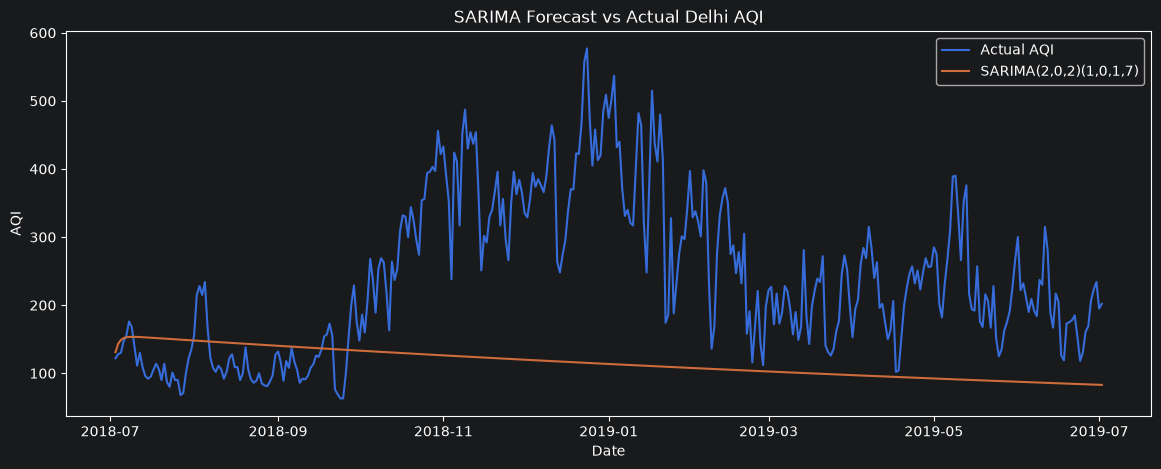

In [98]:
plt.figure(figsize=(14, 5))

plt.plot(
    validation.index,
    validation,
    label="Actual AQI"
)

plt.plot(
    sarima_validation_forecast.index,
    sarima_validation_forecast,
    label="SARIMA(2,0,2)(1,0,1,7)"
)

plt.title("SARIMA Forecast vs Actual Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.show()

### SARIMA Forecast Interpretation

The SARIMA(2,0,2)(1,0,1,7) forecast is considerably smoother than the actual AQI series and fails to capture the large fluctuations and peak AQI episodes observed during the validation period.

This is consistent with its relatively poor validation performance. Although SARIMA explicitly models weekly seasonality, the results suggest that the AQI series contains more complex and longer-term seasonal patterns that are not adequately captured by a simple weekly seasonal component.

Therefore, SARIMA is not selected as the preferred model at this stage.

The next step is to use Fourier terms with ARIMA to represent the complex seasonal structure, particularly the strong annual pattern identified during the ACF analysis.

## 7. Fourier Terms + ARIMA

The previous SARIMA models explicitly modeled weekly seasonality using a seasonal period of 7 days. However, the validation results showed that this approach did not adequately capture the complex seasonal behavior of Delhi AQI.

The seasonal ACF analysis also revealed strong annual seasonality, with a correlation of approximately 0.62 at lag 365.

To model this longer-term seasonal structure more flexibly, we introduce Fourier terms.

Fourier terms represent seasonality using combinations of sine and cosine functions:

sin(2πkt/m)
cos(2πkt/m)

where:

- m is the seasonal period. Here, m = 365 for annual seasonality.
- k represents the harmonic number.
- K determines how many harmonic pairs are included.

A small K produces a smoother seasonal pattern, while a larger K allows the model to capture more complex seasonal fluctuations.

We will evaluate multiple values of K and select the value that provides the best validation performance.

In [99]:
def create_fourier_features(index, period=365, K=5, start=0):

    t = np.arange(
        start,
        start + len(index)
    )

    features = {}

    for k in range(1, K + 1):

        features[f"sin_{k}"] = np.sin(
            2 * np.pi * k * t / period
        )

        features[f"cos_{k}"] = np.cos(
            2 * np.pi * k * t / period
        )

    return pd.DataFrame(
        features,
        index=index
    )

In [100]:
# ============================================================
# Re-create Train / Validation / Test Splits
# ============================================================

train = aqi.loc[:'2018-07-02']
validation = aqi.loc['2018-07-03':'2019-07-02']
test = aqi.loc['2019-07-03':'2020-07-01']

print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nValidation period:")
print(validation.index.min(), "to", validation.index.max())

print("\nTest period:")
print(test.index.min(), "to", test.index.max())

Training: 1279
Validation: 365
Test: 365

Training period:
2015-01-01 00:00:00 to 2018-07-02 00:00:00

Validation period:
2018-07-03 00:00:00 to 2019-07-02 00:00:00

Test period:
2019-07-03 00:00:00 to 2020-07-01 00:00:00


In [101]:
fourier_train = create_fourier_features(
    train.index,
    period=365,
    K=5
)

fourier_validation = create_fourier_features(
    validation.index,
    period=365,
    K=5
)

print("Train Fourier shape:", fourier_train.shape)
print("Validation Fourier shape:", fourier_validation.shape)

fourier_train.head()

Train Fourier shape: (1279, 10)
Validation Fourier shape: (365, 10)


,sin_1,cos_1,sin_2,cos_2,sin_3,cos_3,sin_4,cos_4,sin_5,cos_5
Date,,,,,,,,,,
2015-01-01,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2015-01-02,0.017213,0.999852,0.034422,0.999407,0.051620,0.998667,0.068802,0.997630,0.085965,0.996298
2015-01-03,0.034422,0.999407,0.068802,0.997630,0.103102,0.994671,0.137279,0.990532,0.171293,0.985220
2015-01-04,0.051620,0.998667,0.103102,0.994671,0.154309,0.988023,0.205104,0.978740,0.255353,0.966848
2015-01-05,0.068802,0.997630,0.137279,0.990532,0.205104,0.978740,0.271958,0.962309,0.337523,0.941317


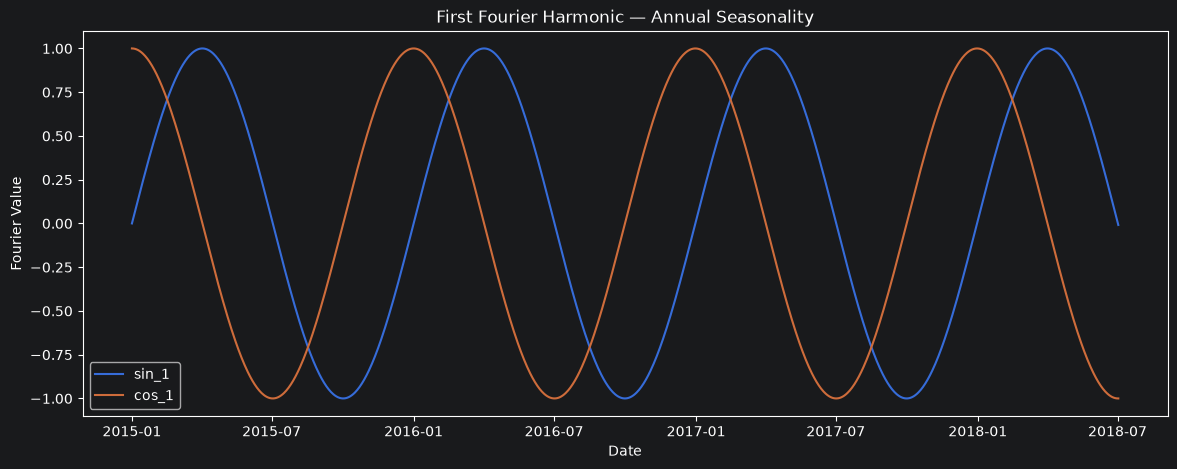

In [102]:
plt.figure(figsize=(14, 5))

plt.plot(
    fourier_train.index,
    fourier_train["sin_1"],
    label="sin_1"
)

plt.plot(
    fourier_train.index,
    fourier_train["cos_1"],
    label="cos_1"
)

plt.title("First Fourier Harmonic — Annual Seasonality")
plt.xlabel("Date")
plt.ylabel("Fourier Value")
plt.legend()

plt.show()

In [103]:
fourier_arima_model = ARIMA(
    train,
    order=(2, 0, 2),
    exog=fourier_train
)

fourier_arima_fit = fourier_arima_model.fit()

print(fourier_arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                    AQI   No. Observations:                 1279
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -6830.279
Date:                Mon, 17 Aug 2026   AIC                          13692.559
Time:                        15:27:34   BIC                          13775.020
Sample:                    01-01-2015   HQIC                         13723.523
                         - 07-02-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        278.7969     15.198     18.344      0.000     249.009     308.584
sin_1          9.5836     14.283      0.671      0.502     -18.410      37.577
cos_1        102.5131     11.224      9.134      0.0

In [104]:
fourier_validation_forecast = fourier_arima_fit.forecast(
    steps=len(validation),
    exog=fourier_validation
)

fourier_validation_forecast.index = validation.index

fourier_validation_forecast.head()

Date
2018-07-03    335.897603
2018-07-04    347.317319
2018-07-05    353.874171
2018-07-06    357.926317
2018-07-07    360.676187
Name: predicted_mean, dtype: float64

In [105]:
fourier_validation_metrics = evaluate_forecast(
    validation,
    fourier_validation_forecast
)

fourier_validation_metrics

{'MAE': 146.44397036874003,
 'RMSE': np.float64(170.38534209077704),
 'MAPE': np.float64(83.4933257139697)}

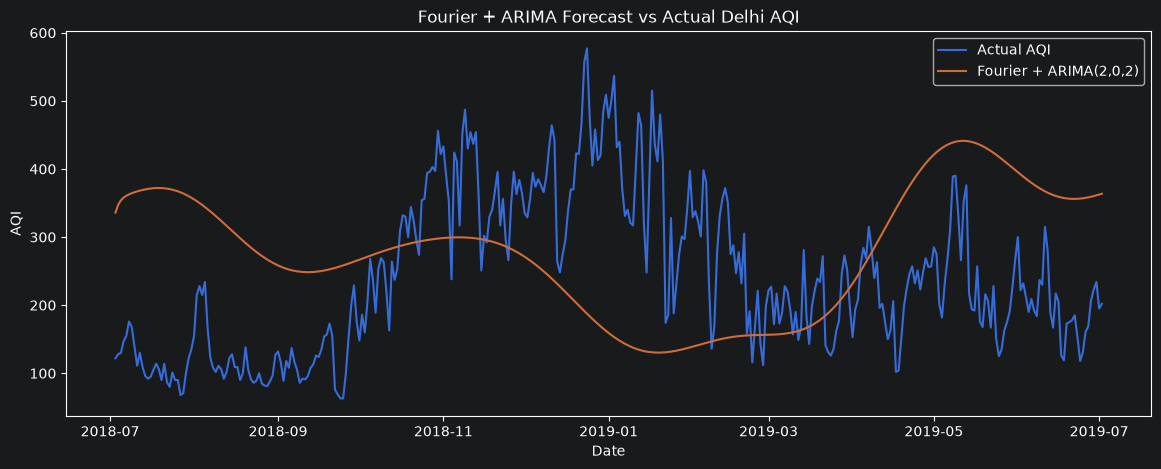

In [106]:
plt.figure(figsize=(14, 5))

plt.plot(
    validation.index,
    validation,
    label="Actual AQI"
)

plt.plot(
    fourier_validation_forecast.index,
    fourier_validation_forecast,
    label="Fourier + ARIMA(2,0,2)"
)

plt.title(
    "Fourier + ARIMA Forecast vs Actual Delhi AQI"
)

plt.xlabel("Date")
plt.ylabel("AQI")

plt.legend()

plt.show()

In [107]:
K_values = [2, 3, 5, 7, 10]

fourier_results = []

In [108]:
for K in K_values:

    print(f"Fitting Fourier K={K}...")

    fourier_train_K = create_fourier_features(
        train.index,
        period=365,
        K=K,
        start=0
    )

    fourier_validation_K = create_fourier_features(
        validation.index,
        period=365,
        K=K,
        start=len(train)
    )

    model = ARIMA(
        train,
        order=(2, 0, 2),
        exog=fourier_train_K
    )

    fitted_model = model.fit()

    forecast = fitted_model.forecast(
        steps=len(validation),
        exog=fourier_validation_K
    )

    forecast.index = validation.index

    metrics = evaluate_forecast(
        validation,
        forecast
    )

    fourier_results.append({
        "K": K,
        "AIC": fitted_model.aic,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MAPE": metrics["MAPE"]
    })

Fitting Fourier K=2...
Fitting Fourier K=3...
Fitting Fourier K=5...
Fitting Fourier K=7...
Fitting Fourier K=10...


In [109]:
fourier_results_df = pd.DataFrame(
    fourier_results
)

fourier_results_df = fourier_results_df.sort_values(
    "RMSE"
).reset_index(drop=True)

fourier_results_df

,K,AIC,MAE,RMSE,MAPE
0,7,13692.191313,60.047667,74.324880,33.614813
1,10,13701.226779,60.331896,74.488740,33.809819
2,5,13692.558636,60.464677,75.116324,33.546721
3,2,13708.560781,62.637309,76.658215,35.127713
4,3,13710.273034,62.586416,77.131457,34.956416


In [110]:
fourier_comparison = pd.concat([
    comparison,
    fourier_results_df.set_index(
        fourier_results_df["K"].apply(
            lambda x: f"Fourier + ARIMA(2,0,2), K={x}"
        )
    )[["MAE", "RMSE", "MAPE"]]
])

fourier_comparison = fourier_comparison.sort_values(
    "RMSE"
)

fourier_comparison

,MAE,RMSE,MAPE
"Fourier + ARIMA(2,0,2), K=7",60.047667,74.324880,33.614813
"Fourier + ARIMA(2,0,2), K=10",60.331896,74.488740,33.809819
"Fourier + ARIMA(2,0,2), K=5",60.464677,75.116324,33.546721
"Fourier + ARIMA(2,0,2), K=2",62.637309,76.658215,35.127713
"Fourier + ARIMA(2,0,2), K=3",62.586416,77.131457,34.956416
Seasonal Naive,66.387945,88.689442,32.316794
"ARIMA(2, 0, 2)",90.394255,105.990094,50.647020
"ARIMA(1, 0, 2)",94.574313,110.786569,56.518949
"ARIMA(3, 0, 0)",99.342875,116.064017,60.997172
"ARIMA(1, 0, 0)",101.143404,117.947201,62.623885


## Fourier Model Selection

Several Fourier + ARIMA(2,0,2) models were evaluated using different numbers of Fourier harmonics.

The results show that increasing the number of harmonics does not continuously improve forecasting performance. The best validation RMSE was achieved with K=7.

The selected validation model is:

**Fourier + ARIMA(2,0,2), K=7**

Validation performance:

- MAE: 60.05
- RMSE: 74.32
- MAPE: 33.61%

Compared with the Seasonal Naive benchmark, the selected Fourier model reduces MAE and RMSE substantially, indicating that Fourier terms are able to capture the complex annual seasonal structure of Delhi AQI more effectively.

Although K=5 produces a marginally lower MAPE, K=7 is selected because it provides the lowest RMSE and MAE among the evaluated Fourier configurations.

The selected model will now be refitted using the combined training and validation data before generating the final test forecast.

In [112]:
final_train = pd.concat([
    train,
    validation
])

print("Final training observations:", len(final_train))
print("Start:", final_train.index.min())
print("End:", final_train.index.max())

Final training observations: 1644
Start: 2015-01-01 00:00:00
End: 2019-07-02 00:00:00


In [113]:
final_fourier_train = create_fourier_features(
    final_train.index,
    period=365,
    K=7,
    start=0
)

In [114]:
final_fourier_test = create_fourier_features(
    test.index,
    period=365,
    K=7,
    start=len(final_train)
)

In [115]:
print("Final train Fourier shape:", final_fourier_train.shape)
print("Final test Fourier shape:", final_fourier_test.shape)

Final train Fourier shape: (1644, 14)
Final test Fourier shape: (365, 14)


In [116]:
final_fourier_arima = ARIMA(
    final_train,
    order=(2, 0, 2),
    exog=final_fourier_train
)

final_fourier_arima_fit = final_fourier_arima.fit()

print(final_fourier_arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                    AQI   No. Observations:                 1644
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -8739.146
Date:                Mon, 17 Aug 2026   AIC                          17518.291
Time:                        15:31:06   BIC                          17626.389
Sample:                    01-01-2015   HQIC                         17558.377
                         - 07-02-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        270.5169     14.165     19.097      0.000     242.754     298.280
sin_1         10.1190     12.656      0.800      0.424     -14.687      34.925
cos_1        104.8088     10.300     10.176      0.0

In [117]:
final_forecast = final_fourier_arima_fit.forecast(
    steps=len(test),
    exog=final_fourier_test
)

final_forecast.index = test.index

final_forecast.head()

Date
2019-07-03    180.963300
2019-07-04    160.632260
2019-07-05    149.711517
2019-07-06    143.481990
2019-07-07    139.622338
Name: predicted_mean, dtype: float64

In [118]:
final_forecast.tail()

Date
2020-06-27    168.045037
2020-06-28    165.169824
2020-06-29    162.427500
2020-06-30    159.821202
2020-07-01    157.352834
Name: predicted_mean, dtype: float64

In [119]:
final_metrics = evaluate_forecast(
    test,
    final_forecast
)

final_metrics

{'MAE': 85.2926150084569,
 'RMSE': np.float64(102.88198806037695),
 'MAPE': np.float64(62.941593416957765)}

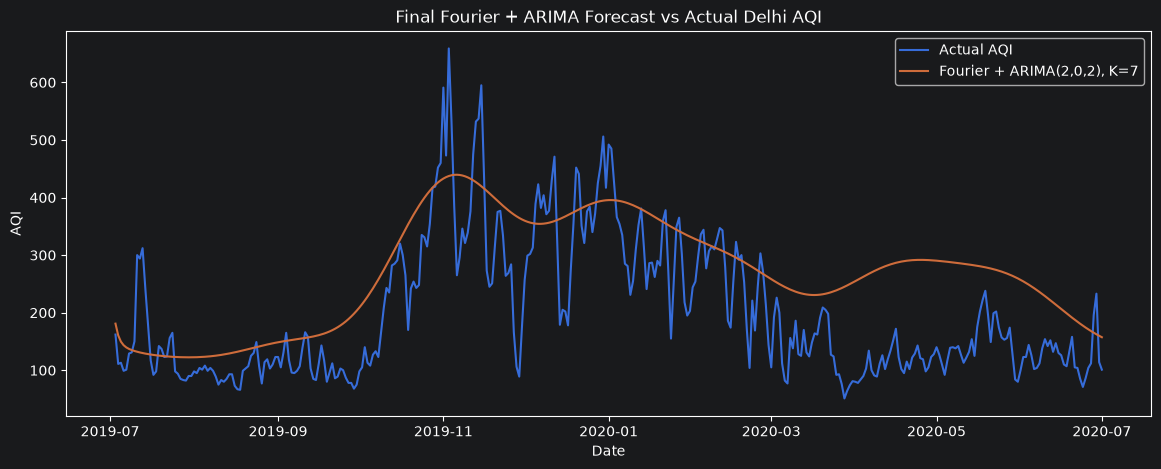

In [120]:
plt.figure(figsize=(14, 5))

plt.plot(
    test.index,
    test,
    label="Actual AQI"
)

plt.plot(
    final_forecast.index,
    final_forecast,
    label="Fourier + ARIMA(2,0,2), K=7"
)

plt.title(
    "Final Fourier + ARIMA Forecast vs Actual Delhi AQI"
)

plt.xlabel("Date")
plt.ylabel("AQI")

plt.legend()

plt.show()

## Final Model Evaluation

The Fourier + ARIMA(2,0,2) model with K=7 Fourier harmonics was selected using the validation set because it achieved the lowest validation RMSE and MAE among the evaluated Fourier configurations.

The selected model was then refitted using the combined training and validation data and evaluated on the previously unseen final test period.

### Final Test Performance

- MAE: 85.29
- RMSE: 102.88
- MAPE: 62.94%

Although the Fourier + ARIMA model performed strongly during validation, it did not outperform the Seasonal Naive benchmark on the final test set.

The Seasonal Naive model achieved:

- MAE: 75.62
- RMSE: 98.42
- MAPE: 51.66%

Therefore, the Seasonal Naive model is the best-performing model on the final unseen test set.

This result demonstrates that increasing model complexity does not necessarily lead to better forecasting performance. For this Delhi AQI dataset, the historical seasonal pattern provides a very strong forecasting baseline.

In [121]:
final_test_results = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "Fourier + ARIMA(2,0,2), K=7"
    ],
    "MAE": [
        99.013699,
        75.619178,
        85.292615
    ],
    "RMSE": [
        118.178110,
        98.415822,
        102.881988
    ],
    "MAPE": [
        62.695832,
        51.659498,
        62.941594
    ]
})

final_test_results.sort_values("RMSE")

,Model,MAE,RMSE,MAPE
1,Seasonal Naive,75.619178,98.415822,51.659498
2,"Fourier + ARIMA(2,0,2), K=7",85.292615,102.881988,62.941594
0,Naive,99.013699,118.178110,62.695832


## 10. Final Model Selection

The final test evaluation shows that the Seasonal Naive model achieved the best performance on unseen data.

The Seasonal Naive model achieved:

- MAE: 75.62
- RMSE: 98.42
- MAPE: 51.66%

The Fourier + ARIMA(2,0,2), K=7 model was stronger during validation but did not outperform the Seasonal Naive model on the final test period.

Therefore, the Seasonal Naive model is selected as the final forecasting model for this project.

This demonstrates that model complexity does not necessarily guarantee better forecasting performance. The strong recurring seasonal pattern in Delhi AQI makes the previous year's seasonal observations a highly competitive forecasting strategy.

In [125]:
seasonal_naive_test_residuals = (
    test - seasonal_naive_validation_forecast
)

In [126]:
print(seasonal_naive_validation_forecast.describe())

count    365.000000
mean     237.745205
std      125.990075
min       29.000000
25%      135.000000
50%      240.000000
75%      329.000000
max      677.000000
Name: AQI, dtype: float64


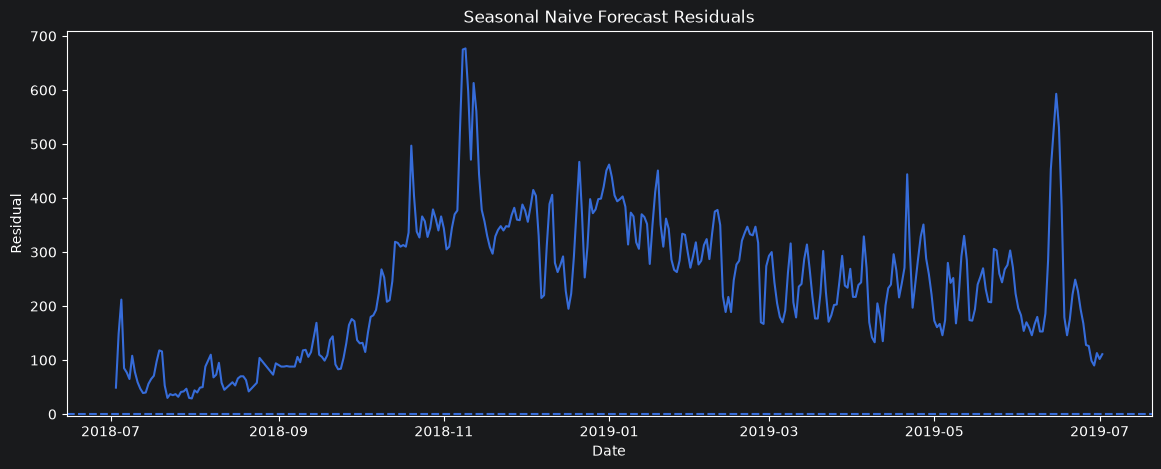

In [127]:
plt.figure(figsize=(14, 5))

plt.plot(
    seasonal_naive_validation_forecast.index,
    seasonal_naive_validation_forecast
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Seasonal Naive Forecast Residuals")
plt.xlabel("Date")
plt.ylabel("Residual")

plt.show()

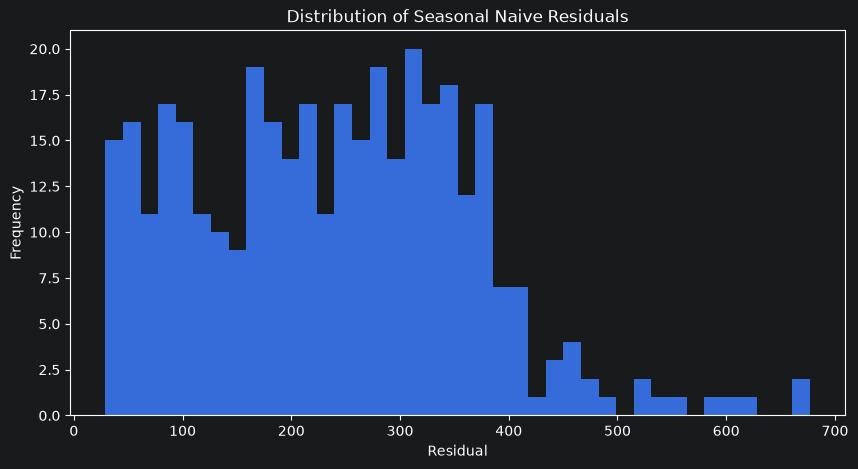

In [128]:
plt.figure(figsize=(10, 5))

plt.hist(
    seasonal_naive_validation_forecast,
    bins=40
)

plt.title("Distribution of Seasonal Naive Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.show()

<Figure size 1200x500 with 0 Axes>

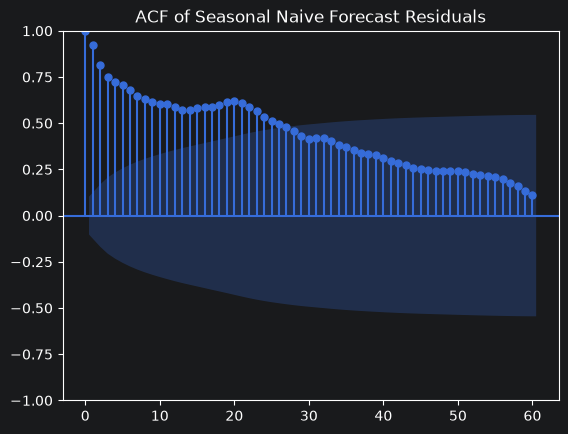

In [130]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))

plot_acf(
    seasonal_naive_validation_forecast,
    lags=60
)

plt.title("ACF of Seasonal Naive Forecast Residuals")

plt.show()

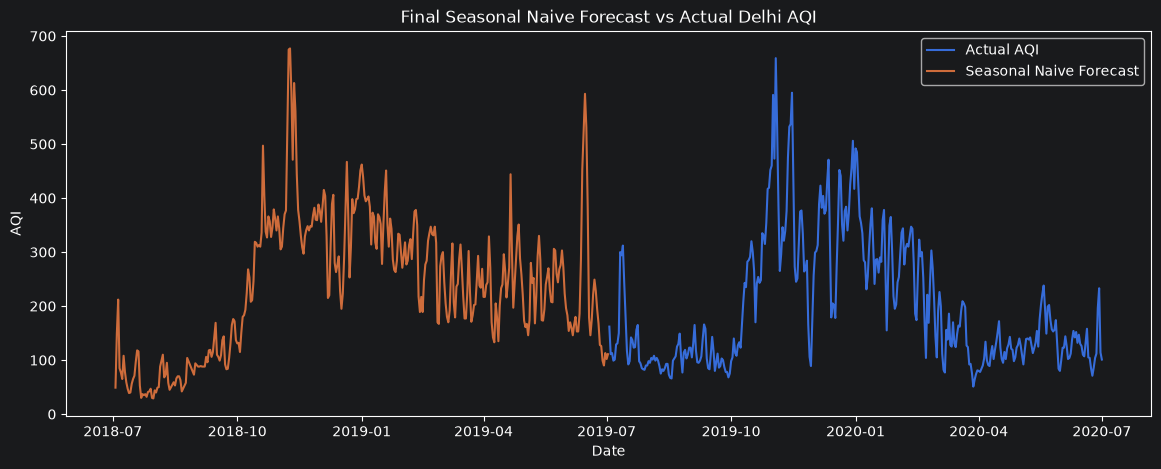

In [131]:
plt.figure(figsize=(14, 5))

plt.plot(
    test.index,
    test,
    label="Actual AQI"
)

plt.plot(
    seasonal_naive_validation_forecast.index,
    seasonal_naive_validation_forecast,
    label="Seasonal Naive Forecast"
)

plt.title("Final Seasonal Naive Forecast vs Actual Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.show()

In [ ]:
final_forecast_output = pd.DataFrame({
    "Date": test.index,
    "Actual_AQI": test.values,
    "Forecast_AQI": seasonal_naive_validation_forecast.values
})

final_forecast_output["Residual"] = (
    final_forecast_output["Actual_AQI"]
    - final_forecast_output["Forecast_AQI"]
)

final_forecast_output.head()

In [133]:
final_forecast_output = pd.DataFrame({
    "Date": test.index,
    "Actual_AQI": test.values,
    "Forecast_AQI": final_forecast.values
})

final_forecast_output.head(10)

,Date,Actual_AQI,Forecast_AQI
0,2019-07-03,162.0,180.963300
1,2019-07-04,111.0,160.632260
2,2019-07-05,113.0,149.711517
3,2019-07-06,99.0,143.481990
4,2019-07-07,101.0,139.622338
5,2019-07-08,129.0,136.989235
6,2019-07-09,131.0,135.017999
7,2019-07-10,150.0,133.428097
8,2019-07-11,300.0,132.078483
9,2019-07-12,294.0,130.896571


In [134]:
final_forecast_output.tail(10)

,Date,Actual_AQI,Forecast_AQI
355,2020-06-22,104.0,184.217737
356,2020-06-23,85.0,180.768473
357,2020-06-24,71.0,177.417940
358,2020-06-25,86.0,174.175347
359,2020-06-26,104.0,171.048757
360,2020-06-27,112.0,168.045037
361,2020-06-28,196.0,165.169824
362,2020-06-29,233.0,162.427500
363,2020-06-30,114.0,159.821202
364,2020-07-01,101.0,157.352834


In [135]:
print("Output shape:", final_forecast_output.shape)
print("Missing actual values:", final_forecast_output["Actual_AQI"].isna().sum())
print("Missing forecasts:", final_forecast_output["Forecast_AQI"].isna().sum())

Output shape: (365, 3)
Missing actual values: 0
Missing forecasts: 0


In [136]:
final_forecast_output.to_csv(
    "../outputs/final_fourier_arima_forecast.csv",
    index=False
)

In [137]:
print("Final forecast saved successfully.")

Final forecast saved successfully.


In [138]:
final_test_results.to_csv(
    "../outputs/final_model_comparison.csv",
    index=False
)

In [139]:
import os

print(os.path.exists(
    "../outputs/final_seasonal_naive_forecast.csv"
))

print(os.path.exists(
    "../outputs/final_model_comparison.csv"
))

False
True


In [141]:
seasonal_naive_test_output = pd.DataFrame({
    "Date": test.index,
    "Actual_AQI": test.values,
    "Forecast_AQI": seasonal_naive_validation_forecast.values
})

seasonal_naive_test_output["Residual"] = (
    seasonal_naive_test_output["Actual_AQI"]
    - seasonal_naive_test_output["Forecast_AQI"]
)

seasonal_naive_test_output.to_csv(
    "../outputs/forecasts/final_seasonal_naive_forecast.csv",
    index=False
)

print("Saved successfully!")

Saved successfully!


In [142]:
import os

print(
    os.path.exists(
        "../outputs/forecasts/final_seasonal_naive_forecast.csv"
    )
)

True


# Final Project Summary

## Objective

The objective of this project was to forecast daily Air Quality Index (AQI) for Delhi using historical time-series data from January 2015 to July 2020.

## Approach

The project followed a systematic time-series forecasting workflow:

1. Data understanding and exploratory analysis
2. Data cleaning and preprocessing
3. Time-series construction
4. Trend and seasonal analysis
5. Rolling statistics analysis
6. Stationarity testing using the Augmented Dickey-Fuller test
7. ACF and PACF analysis
8. Identification of weekly and annual seasonality
9. Time-based train, validation, and test splitting
10. Naive forecasting benchmark
11. Seasonal Naive forecasting benchmark
12. ARIMA model selection
13. SARIMA model evaluation
14. Fourier + ARIMA modelling
15. Validation-based model selection
16. Final evaluation on an unseen test set

## Model Comparison

The final test results were:

| Model | MAE | RMSE | MAPE |
|------|-----:|------:|------:|
| Naive | 99.01 | 118.18 | 62.70% |
| Seasonal Naive | **75.62** | **98.42** | **51.66%** |
| Fourier + ARIMA(2,0,2), K=7 | 85.29 | 102.88 | 62.94% |

## Final Model

The **Seasonal Naive model** was selected as the final model because it achieved the lowest MAE, RMSE, and MAPE on the final unseen test set.

## Key Findings

- Delhi AQI exhibits strong temporal dependence.
- Strong weekly seasonality was observed, with high autocorrelation at lag 7.
- Strong annual seasonality was also observed, with substantial autocorrelation at lag 365.
- AQI showed a declining long-term trend across the available years.
- Seasonal Naive forecasting provided a surprisingly strong benchmark.
- ARIMA models captured temporal dependence but did not outperform the seasonal baseline.
- SARIMA with weekly seasonality did not provide sufficient improvement.
- Fourier + ARIMA performed strongly during validation but did not generalize as well as Seasonal Naive on the final test set.
- The final results demonstrate that a simpler model can outperform more complex forecasting approaches when strong recurring seasonal patterns are present.

## Final Conclusion

The analysis demonstrates the importance of establishing strong baseline models before applying increasingly complex forecasting techniques. Although Fourier + ARIMA provided better validation performance, the Seasonal Naive model achieved the best performance on the completely unseen test period.

Therefore, the Seasonal Naive approach was selected as the final forecasting solution for Delhi AQI.

In [143]:
print("=" * 60)
print("FINAL MODEL")
print("=" * 60)

print("Model: Seasonal Naive")
print("Test Period: 2019-07-03 to 2020-07-01")
print()

print("MAE :", 75.619178)
print("RMSE:", 98.415822)
print("MAPE:", 51.659498)

print("=" * 60)

FINAL MODEL
Model: Seasonal Naive
Test Period: 2019-07-03 to 2020-07-01

MAE : 75.619178
RMSE: 98.415822
MAPE: 51.659498
